# ACESO — chromatin accessibility from a sparse RNA panel

A spatial transcriptomics panel measures a few hundred genes per cell and no chromatin at all.
**ACESO** reads that panel and predicts the cell's accessibility over the whole genome at 32 bp
resolution, so the same tissue section can be asked which regulatory element is open in which cell.

It is three stages, and the method is the middle one:

| Stage | What it does | Epione |
|---|---|---|
| 0 | a chromatin state space `z`: EpiAgent on the reference's own ATAC, cCREs lifted over for a non-human genome | `epi.models.aceso.lift_ccre_bed`, `finetune_ufe`, `embed_cells` |
| 1 | **the encoder**: scGPT maps *any* gene subset at *any* depth onto `z` | `epi.models.aceso.train_v1_encoder` |
| 2 | the decoder: DNA + `z` -> the cell's 32 bp profile over 524 kb | `epi.models.aceso.train_v1_decoder` |
| — | panel sampling that makes stage 1 panel-agnostic | `epi.models.aceso.PanelSpace`, `PanelSampler`, `thin_counts` |
| — | prediction, metrics, figures | `epi.models.aceso.predict_profiles`, `pseudobulk_pearson`, `plot_tracks` |

What defines ACESO is stage 1: one fixed state space that any panel maps into, so a new dataset
needs no refit. The decoder that reads `z` out is an implementation choice, and the released v1
decoder is an AlphaGenome 32 bp trunk with a linear per-cell read-out.

**Data.** The v1 model was trained on one mouse embryo multiome time course (GEO GSE205117, 43,123
cells, E7.5–E8.75) and tested on a second one that entered no fit (GSE280587). This notebook shows
the API on that training recipe, and draws the released model's predictions at the *Myh6* / *Myh7*
locus from the result files of the paper run; every path is an environment variable with a default,
and a cell whose input is absent says so and moves on.

## Setup

In [1]:
import os
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from epione.models import aceso

aceso.paper_style()          # 12 pt text, 13 pt titles, Arial in the SVG: the paper's typography
ROOT = pathlib.Path(os.environ.get("EPIONE_ROOT", "."))
print(aceso.__doc__.splitlines()[0])

ACESO — ACcessibility Estimation from Spatial transcriptOmics.


## Part 1 · Panel-agnostic sampling

The encoder is trained on gene subsets, never on one vendor panel. Every batch draws a panel size,
draws the genes, and thins the counts to the depth that platform would have delivered — a MERFISH
cell carries about 1–8 % of the UMIs of a droplet cell, so training on undiluted counts would teach
the encoder a depth it will never see.

`PanelSpace` holds what a panel can be drawn from (the genes, their variability rank, the depth
distribution to thin to); `PanelSampler` draws one; `thin_counts` does the binomial thinning.

In [2]:
rng = np.random.default_rng(0)
genes = np.array([f"G{i}" for i in range(2000)], dtype=object)
counts = rng.poisson(1.5, size=(500, 2000))                      # stand-in for the reference's RNA

space = aceso.PanelSpace(genes=genes, vocab_ids=np.arange(2000),
                         target=np.arange(480),                  # the vendor panel: 480 genes
                         pool=np.arange(2000))                   # random panels come from the HVGs
sampler = aceso.PanelSampler(space, target_depths=rng.lognormal(5.3, 0.5, 500), mode="mixed")
for _ in range(5):
    cols, scale = sampler.draw(rng)
    kind = "vendor panel" if len(cols) == len(space.target) else "random panel"
    print(f"{kind:13s} {len(cols):>4d} genes, depth scale {scale:.2f}")

random panel   107 genes, depth scale 0.33
random panel   739 genes, depth scale 2.48
vendor panel   480 genes, depth scale 1.00
vendor panel   480 genes, depth scale 1.00
vendor panel   480 genes, depth scale 1.00


`thin_counts` takes the drawn depth to the cells. The panel that comes out is sparse in exactly the
way a real one is: most genes zero, a few tens of counts in total.

In [3]:
import scipy.sparse as sp

M = sp.csr_matrix(counts[:, cols].astype(np.float32))
target_depth = np.full(M.shape[0], 210.0)                        # the median MERFISH cell
T = aceso.thin_counts(M, target_depth, rng)
print(f"before {M.sum(1).mean():.0f} counts per cell, after {T.sum(1).mean():.0f}; "
      f"{(np.diff(T.indptr) == 0).mean():.0%} of cells empty")

before 721 counts per cell, after 209; 0% of cells empty


## Part 2 · Stage 1, the encoder

`V1EncoderConfig` is the released recipe: scGPT's whole-human checkpoint, distilled onto the
fine-tuned EpiAgent `z` with `(1 - cos) + symmetric InfoNCE(tau 0.07)`, Adam 1e-4, StepLR 0.9 per
epoch, and the mixed panel sampler above. `panel_mode` is the one knob that changes the claim:
`mixed` is ACESO, `fixed` trains on one panel only, `random` never shows the model the vendor panel
and so tests panel generalisation outright.

In [4]:
cfg = aceso.V1EncoderConfig(out="runs/stage1_mixed", target="epiagent_z.h5ad", panel_mode="mixed")
for f in ("panel_mode", "p_merfish", "min_genes", "max_genes", "pool", "epochs", "lr", "tau", "patience"):
    print(f"{f:12s} {getattr(cfg, f)}")

panel_mode   mixed
p_merfish    0.5
min_genes    100
max_genes    1000
pool         5000
epochs       40
lr           0.0001
tau          0.07
patience     5


Training is a GPU job of a few hours; it is a function call, or the same thing from the command
line. Splits are by sample, never by cell: cells from one channel share ambient RNA and batch, and a
cell-level split leaks all of it.

```bash
python -m epione.models.aceso._v1_encoder \
    --out runs/stage1_mixed --target epiagent_z.h5ad --panel-mode mixed
```

```python
aceso.train_v1_encoder(cfg)        # writes best.pt, z_pred_merfish_depth.npy, metrics.tsv, train.log
```

`metrics.tsv` reports the encoder on the held-out samples for the vendor panel, for random panels of
100 / 250 / 500 / 1,000 genes, and for the full transcriptome, which is the upper bound of the RNA
side.

## Part 3 · Stage 2, the decoder

The decoder sees 524,288 bp of DNA and one cell state, and predicts 6,144 bins of 32 bp. The trunk is
AlphaGenome's, frozen, with LoRA and LoCon adapters; the per-cell read-out is linear in `z`.

`V1DecoderConfig` carries the terms that were added one at a time and kept only where they paid:
`spec_weight` (a correlation loss across the cells of a sequence), `within_weight` (a contrast
between two stages of the same cell type), `cfg_drop` (classifier-free guidance), and the axis
contrast that the released checkpoint finished on.

In [5]:
dcfg = aceso.V1DecoderConfig(out="runs/decoder_axes", backbone="alphagenome", decoder="scooby")
for f in ("backbone", "decoder", "spec_weight", "within_weight", "within_frac", "within_pool", "cfg_drop"):
    print(f"{f:14s} {getattr(dcfg, f)}")

backbone       alphagenome
decoder        scooby
spec_weight    0.0
within_weight  0.0
within_frac    0.5
within_pool    32
cfg_drop       0.0


```bash
python -m epione.models.aceso._v1_decoder \
    --out runs/decoder_axes --embedding embedding.parquet \
    --backbone alphagenome --decoder scooby --within-weight 1 --within-frac 0.5
```

The run writes one JSON record per logged step to `train.log`, which is what `plot_training_curve`
reads.

432 records, 8,000 steps; best val Pearson(log) 0.1671


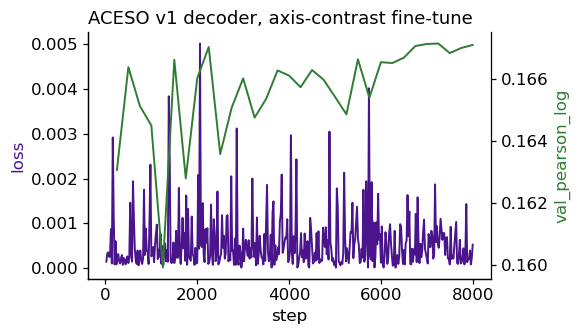

In [6]:
LOG = pathlib.Path(os.environ.get("ACESO_V1_RUN", ROOT / "gse205117/scooby/runs/ag_scooby_axesw_ft160k_mixed"))
if (LOG / "train.log").exists():
    df = aceso.read_training_log(LOG)
    fig, ax = aceso.plot_training_curve(LOG, keys=("loss", "val_pearson_log"), show=False)
    ax[0].set_title("ACESO v1 decoder, axis-contrast fine-tune", loc="left", fontsize=13)
    print(f"{len(df)} records, {int(df['step'].max()):,} steps; "
          f"best val Pearson(log) {df['val_pearson_log'].max():.4f}")
else:
    print(f"no run at {LOG}; set $ACESO_V1_RUN to a directory holding train.log")

## Part 4 · What the model predicts, drawn the way the paper draws it

The point of the whole construction is that the *same DNA* gives *different* chromatin in different
cells, and that the difference is right. `plot_tracks` puts the measured and the predicted profile of
each cell type over one locus, with the called elements and the gene model underneath — the shape of
Figure 3e.

Here: the *Myh6* / *Myh7* locus on chr14 in the held-out embryo dataset, cardiomyocytes against two
cell types that should not open it.

chr14:54,853,632-55,050,240, 3 cell types


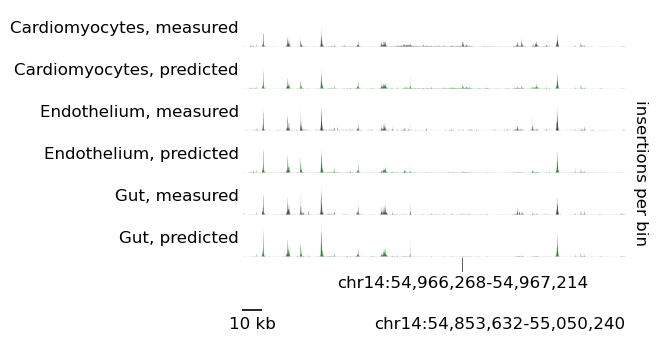

In [7]:
T7 = pathlib.Path(os.environ.get("ACESO_FIG3_TRACKS", ROOT / "paper/fig3/results/t7"))
npz = T7 / "tracks_t084.npz"
if npz.exists():
    z = np.load(npz, allow_pickle=True)
    types = list(z["types"])
    show = [t for t in ("Cardiomyocytes", "Endothelium", "Gut") if t in types]
    tracks, colors = {}, {}
    for t in show:
        j = types.index(t)
        tracks[f"{t}, measured"] = z["measured"][:, j]
        tracks[f"{t}, predicted"] = z["ag32_scooby_axesw_s4000"][:, j]
    # the element this locus was chosen for, read from the panel's own table
    meta = pd.read_csv(T7 / "panel_type_tracks.tsv", sep="\t")
    peak = meta.loc[meta.locus == "t084", "peak"].iloc[0]
    lo, hi = (int(x.replace(",", "")) for x in peak.split(":")[1].split("-"))
    regions = pd.DataFrame({"start": [lo], "end": [hi]})
    fig, axes = aceso.plot_tracks(tracks, chrom=str(z["chrom"]), start=int(z["start"]), bin_size=32,
                                  regions=regions, ylabel="insertions per bin", show=False)
    print(f"{str(z['chrom'])}:{int(z['start']):,}-{int(z['end']):,}, {len(show)} cell types")
else:
    print(f"no tracks at {npz}; set $ACESO_FIG3_TRACKS, or write your own with "
          f"aceso.predict_profiles(...) and pass the arrays to aceso.plot_tracks")

Accessibility predicted for one cell type and measured in the same cells are two different
quantities: a rate against a Poisson-starved count. `epi.models.aceso` scores them the way the paper
does — per cell with `knn_smoothed_pearson`, per group with `pseudobulk_pearson`, and across cell
types with the difference correlation, which is the metric that asks whether the *differences*
between cell types are right rather than whether the average profile is.

In [8]:
rng = np.random.default_rng(0)
obs = rng.poisson(0.4, size=(6144, 60)).astype(float)            # bins x cells, as the decoder writes them
pred = np.clip(obs + rng.normal(0, 0.3, obs.shape), 0, None)
groups = ["Cardiomyocytes"] * 30 + ["Endothelium"] * 30
r = aceso.pseudobulk_pearson(pred, obs, groups, min_cells=20)
for g, v in r["per_group"].items():
    print(f"{g:16s} r = {float(v):.3f}")
print(f"{'differential':16s} r = {r['differential']:.3f}")

Cardiomyocytes   r = 0.926
Endothelium      r = 0.927
differential     r = 0.925


## Notes

* Stage 0 (EpiAgent) needs its own environment because of flash-attn; stages 1 and 2 need the
  official scGPT and scooby sources and the AlphaGenome weights. `epi.models.aceso.require_sites`
  resolves all of them at start-up and fails there rather than per item, which is the difference
  between a three-second error and a wasted allocation.
* Cell-type labels in the benchmark are RNA-derived, so a classifier on the RNA panel itself scores
  above ACESO's predicted chromatin. The model transfers type identity into chromatin space; it does
  not create it.
* The decoder's within-type terms are the part that is hardest to make pay. On this reference the
  cardiomyocytes are 2 % of the cells and all from the primitive heart tube, so there is little
  within-type structure to learn; that is the data, not the architecture, and it is why v2 trains on
  a corpus (see the ACESO corpus tutorial).